# 5장 — Episode에서 배우는 Monte Carlo Prediction

주사위의 표본 평균에서 시작해 교재 GridWorld의 First/Every-visit MC를 비교한다.
환경 수집과 학습을 분리하고 Return·가치 갱신에는 ModularRL을 사용한다.

[원본 Notebook](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/notebooks/05_montecarlo.ipynb) · [실습 대응표](README.md)
MC Control과 Off-policy MC Control은 현재 미구현이며 아래에서 명시적으로 구분한다.

## 1. Import와 설정

In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

from modular_rl.data import Episode, Transition
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation
from modular_rl.component.estimator import TabularVEstimator
from modular_rl.component.target_generator import MonteCarloReturnGenerator
from modular_rl.learner import MCPredictionLearner
from modular_rl.environment import make_dlfs4_gridworld_env, DLFS4_START_STATE, collect_episode
from modular_rl.dp import uniform_policy, policy_evaluation
from plotting import plot_grid

SEED, GAMMA, EPISODES = 7, 0.9, 1000
rng = np.random.default_rng(SEED)
plt.close('all')

## 2. 주사위와 표본 평균 — `dice.py`

공정한 주사위 두 개의 합의 기댓값은 7이다. 아래는 독립 확률 표본의 통계 실습이다.
RL 상태가치 업데이트를 여기서 구현하는 것은 아니다. 원본의 1,000개 표본을 사용하되 모든 중간값 대신 그래프를 표시한다.

sample mean: 7.079 | exact mean: 7


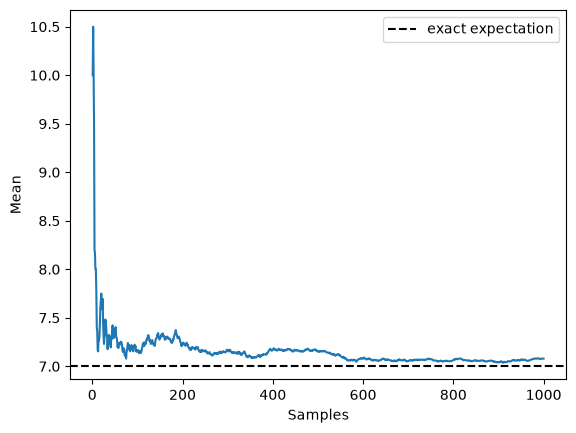

In [2]:
dice = rng.integers(1, 7, size=(1000, 2)).sum(axis=1)
running_mean = np.cumsum(dice) / np.arange(1, len(dice) + 1)
print('sample mean:', running_mean[-1], '| exact mean: 7')
plt.plot(np.arange(1, len(dice) + 1), running_mean)
plt.axhline(7, color='black', linestyle='--', label='exact expectation')
plt.xlabel('Samples'); plt.ylabel('Mean'); plt.legend(); plt.show()

## 3. MC Return과 방문 규칙

$$G_t=r_{t+1}+\gamma G_{t+1},\qquad G_T=0$$

Return은 Generator가 역순으로 계산한다. First-visit는 **시간 순서의 첫 방문**, Every-visit는 모든 방문을 사용한다.
상태 `[1,2,1]`, 보상 `[1,2,3]`, γ=1이면 Return은 `[6,5,3]`이다.
상태1은 First에서 6, Every에서 (6+3)/2=4.5가 된다.

In [3]:
toy_episode = Episode((Transition(1, 0, 1., 2, False, False),
                       Transition(2, 0, 2., 1, False, False),
                       Transition(1, 0, 3., 0, True, False)))
returns = MonteCarloReturnGenerator(1).generate(torch.tensor([1., 2., 3.]))
torch.testing.assert_close(returns, torch.tensor([6., 5., 3.]))
print('returns:', returns.tolist())

returns: [6.0, 5.0, 3.0]


In [4]:
for mode, expected in (('first', 6.), ('every', 4.5)):
    toy_model = Model(IdentityRepresentation(), TabularVEstimator(3)).double()
    toy_learner = MCPredictionLearner(toy_model, MonteCarloReturnGenerator(1), visit_mode=mode)
    toy_learner.learn(toy_episode)
    value = toy_model.forward(1).values.v.item()
    assert value == expected
    print(mode, '| V(1):', value, '| count:', toy_learner.visit_counts[1].item())

first | V(1): 6.0 | count: 1
every | V(1): 4.5 | count: 2


## 4. 교재 Gymnasium 환경과 고정 Policy — `mc_eval.py`

원본처럼 `(2,0)`에서 시작하고 4개 행동을 균등하게 고른다. γ=.9, 1,000 Episode다.
Env는 reset/step과 Outcome RNG를, 호출자는 행동 선택과 별도 RNG를 담당한다.
DP 참조값은 같은 `env.unwrapped.mdp`에서 계산한다. 벽은 State ID가 없고 목표는 RMSE에서 제외한다.

In [5]:
env = make_dlfs4_gridworld_env(max_episode_steps=2000)
mdp = env.unwrapped.mdp
states = np.arange(mdp.n_states)
nonterminal = np.setdiff1d(states, mdp.terminal_states)
policy = uniform_policy(mdp)
reference = policy_evaluation(mdp, policy, gamma=GAMMA, theta=1e-10)
assert reference.converged
action_rng = np.random.default_rng(SEED + 1)
select_action = lambda state: int(action_rng.choice(mdp.n_actions, p=policy[state]))

## 5. Model과 Learner 조립

두 Model은 독립적인 V와 Count를 가진다. Learner가 Incremental Sample Average,
$$N(s)\leftarrow N(s)+1,\qquad V(s)\leftarrow V(s)+[G-V(s)]/N(s)$$
를 사용한다. Notebook에서는 계산을 재구현하지 않는다.

In [6]:
first_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
every_model = Model(IdentityRepresentation(), TabularVEstimator(mdp.n_states)).double()
first = MCPredictionLearner(first_model, MonteCarloReturnGenerator(GAMMA), visit_mode='first')
every = MCPredictionLearner(every_model, MonteCarloReturnGenerator(GAMMA), visit_mode='every')

## 6. Gymnasium 환경에서 Episode 수집 → 같은 Episode 학습

`collect_episode(env, select_action)`는 reset → step을 반복해 한 Episode를 수집한다.
MC는 완료된 Episode 전체를 learn에 넘긴다. TimeLimit(2,000 Step)의 truncated-only 조각은
학습하지 않고 실험을 중단한다. Env는 처음에만 seed를 설정하며 이후 reset은 RNG stream을 계속 사용한다.

In [7]:
history, steps = [], 0
try:
    for number in range(1, EPISODES + 1):
        episode = collect_episode(env, select_action, seed=SEED if number == 1 else None)
        if not episode.terminated:
            raise RuntimeError('Incomplete MC episode: increase max_episode_steps or inspect the policy')
        first.learn(episode)
        every.learn(episode)
        steps += len(episode)
        if number % 100 == 0:
            values = [model.forward(states).values.v.numpy() for model in (first_model, every_model)]
            errors = [np.sqrt(np.mean((v[nonterminal] - reference.values[nonterminal]) ** 2)) for v in values]
            history.append((number, *errors, values[0][DLFS4_START_STATE], values[1][DLFS4_START_STATE]))
finally:
    env.close()
print(f'episodes={EPISODES} steps={steps} seed={SEED} gamma={GAMMA}')

episodes=1000 steps=45188 seed=7 gamma=0.9


## 7. 가치·방문 횟수·DP 오차 확인

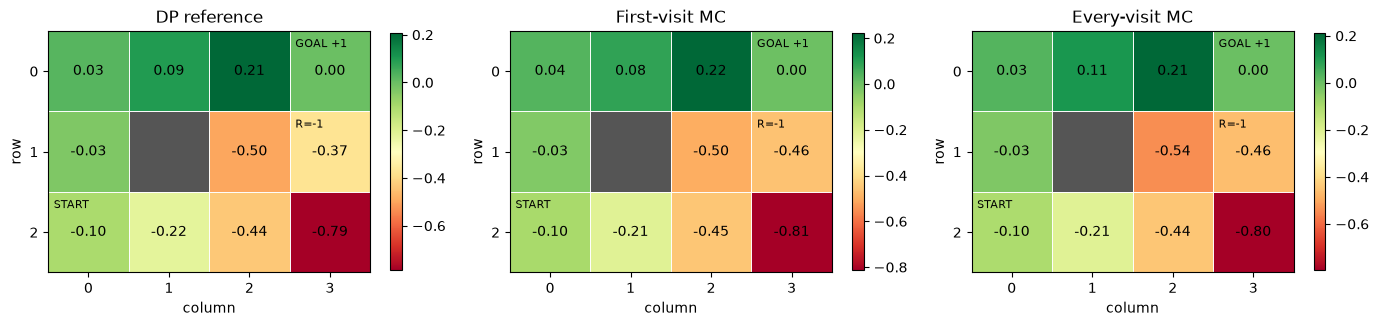

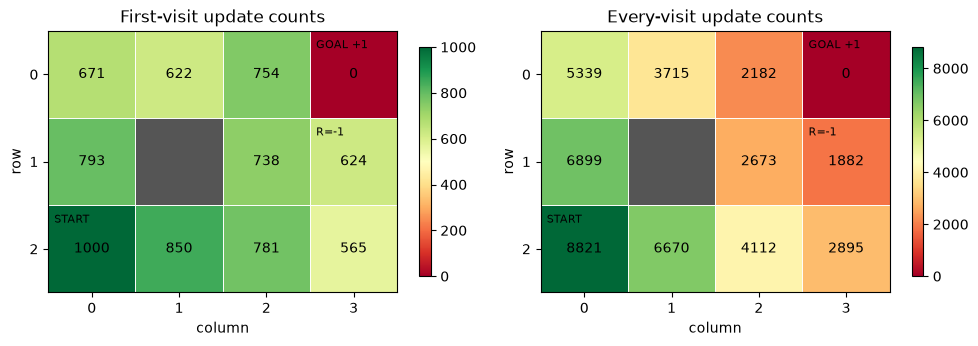

RMSE(first, every): [0.0306 0.0317]


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, title, value in zip(axes, ('DP reference', 'First-visit MC', 'Every-visit MC'),
                          (reference.values, *values)):
    plot_grid(value, title=title, ax=ax)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
plot_grid(first.visit_counts.numpy(), title='First-visit update counts', ax=axes[0], fmt='.0f')
plot_grid(every.visit_counts.numpy(), title='Every-visit update counts', ax=axes[1], fmt='.0f')
plt.tight_layout(); plt.show()
print('RMSE(first, every):', np.round(errors, 4))

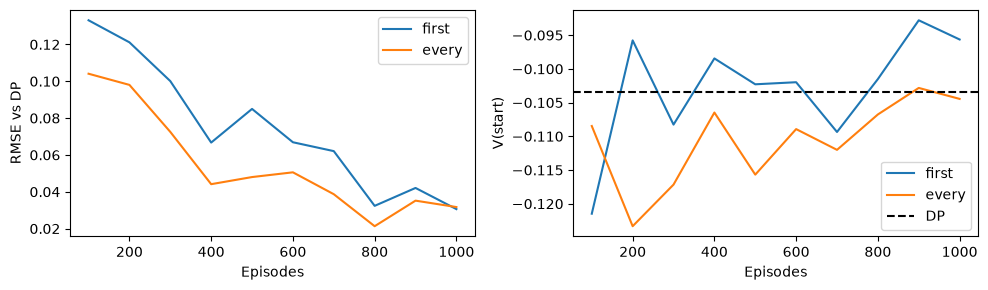

In [9]:
history = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for column, label in ((1, 'first'), (2, 'every')):
    axes[0].plot(history[:, 0], history[:, column], label=label)
    axes[1].plot(history[:, 0], history[:, column + 2], label=label)
axes[0].set(xlabel='Episodes', ylabel='RMSE vs DP')
axes[1].set(xlabel='Episodes', ylabel='V(start)')
axes[1].axhline(reference.values[DLFS4_START_STATE], color='black', linestyle='--', label='DP')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

Count는 학습에 사용한 Return 수이므로 Every ≥ First다. 최종 next_observation은 추가 방문이 아니다.
MC 오차는 표본 변동으로 증가할 수도 있다. 단조 감소를 assert하지 않는다.
학습 재개에는 Model.state_dict와 함께 Learner의 visit_counts도 저장한다.

기존 TabularEpisodeSampler API는 유지하지만 새 실습은 Env를 사용한다. RNG 역할이 분리되었으므로 같은 Seed라도 이전 Sampler의 Episode와 같다고 가정하지 않는다.

## 8. MC Control — 미구현 대응

원본 [`mc_control.py`](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/ch05/mc_control.py)는 γ=.9, α=.1, ε=.1, 10,000 Episode에서
Q와 탐색 정책을 함께 갱신한다. 현재 MC API는 고정 정책의 **V Prediction**이다.
이를 MC Control로 바꾸어 부르거나 Q/정책 개선을 Notebook에 구현하지 않는다.
추가하려면 상태-행동 Return 업데이트와 정책 개선을 담당하는 작은 별도 Learner가 필요하다.

## 9. Importance Sampling — `importance_sampling.py`의 확률변수 실습

$$E_\pi[X]=E_b[\rho(X)X],\qquad \rho(i)=\pi(i)/b(i)$$

Support가 [1,2,3]인 **단일 확률변수**의 NumPy 통계 실습이다. Off-policy RL Learner가 아니다.
원본처럼 100개 표본에서 평균·분산을 확인한다. 유한 표본의 평균이 참값과 정확히 같을 필요는 없다.

In [10]:
support = np.array([1., 2., 3.])
pi, behavior = np.array([.1, .1, .8]), np.array([.2, .2, .6])
on_policy = rng.choice(3, size=100, p=pi)
off_policy = rng.choice(3, size=100, p=behavior)
samples = support[on_policy]
weighted_samples = (pi / behavior)[off_policy] * support[off_policy]
print('exact expectation:', support @ pi)
print('MC mean / variance:', samples.mean(), samples.var())
print('IS mean / variance:', weighted_samples.mean(), weighted_samples.var())

exact expectation: 2.7
MC mean / variance: 2.69 0.3938999999999999
IS mean / variance: 2.825 2.476875


## 10. Off-policy MC Control — 미구현 대응

원본 [`mc_control_offpolicy.py`](https://github.com/WegraLee/deep-learning-from-scratch-4/blob/b82cd6432b4e63ce6a4ab2b925fc74a1227fb06a/ch05/mc_control_offpolicy.py)는 target/behavior Policy와
중요도 비율을 사용해 Q를 갱신한다(γ=.9, α=.2, ε=.1, 10,000 Episode).
현재 해당 Learner와 Return 보정 규칙은 없다. 원본 재귀식의 의미와 Ordinary/Weighted/
Per-decision IS 계약을 정한 뒤 별도로 구현해야 한다. 위 통계 예제가 이를 구현한 것으로 보지 않는다.